# Programming for Data Analysis CA2
Group 3: Yingen, Mehreen, Rishika, Chloe

# ****Research question:****
How does holding a uni degree affect the salary and employment stability and how has it changed relative to Singapore's national workforce between 2013 and 2020?

datasets used:
1. graduate employment survey (given on brightspace)
2. employed residents aged 15 years and over by monthly income, highest qualification, and sex (sourced from data.gov.sg: https://data.gov.sg/datasets/d_156f700d7c7b3e8ca5d4c1771b15110a/view)
3. employment rate of residents aged 25 to 64 (sourced from data.gov.sg: https://data.gov.sg/datasets/d_f50492fe89a0c3a522bf9c04ce3e6380/view)
4. median gross monthly income of full time employed residents (sourced from data.gov.sg: https://data.gov.sg/datasets/d_9cd9c40f22a4e45cac8f8b9d895fd5ce/view)

In [5]:
#imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df1 = pd.read_csv(r"C:\Users\chloe\OneDrive - Singapore Polytechnic\PDAS\CA2\PDASCA2_2A05-2523020-ChloeLim\CA2 Datasets\(1) graduate employment survey modified.csv")
df2 = pd.read_csv(r"C:\Users\chloe\OneDrive - Singapore Polytechnic\PDAS\CA2\PDASCA2_2A05-2523020-ChloeLim\CA2 Datasets\(2) graduate employment survey modified .csv")

#data cleaning
keep_cols = [
    'employment_rate_overall', 'employment_rate_ft_perm',
    'basic_monthly_mean', 'basic_monthly_median',
    'gross_monthly_mean', 'gross_monthly_median',
    'gross_mthly_25_percentile', 'gross_mthly_75_percentile',
    'Key'
]
df2_clean = df2[keep_cols]

merged = pd.merge(df1, df2_clean, on='Key', how='inner')
merged = merged.drop(columns=['Key'])

numeric_cols = [
    'employment_rate_overall', 'employment_rate_ft_perm',
    'basic_monthly_mean', 'basic_monthly_median',
    'gross_monthly_mean', 'gross_monthly_median',
    'gross_mthly_25_percentile', 'gross_mthly_75_percentile'
]
mask_bad_rows = pd.Series(False, index=merged.index)
for col in numeric_cols:
    mask_bad_rows |= (merged[col] == col)
merged = merged[~mask_bad_rows].copy()

for col in numeric_cols:
    merged[col] = merged[col].replace('na', np.nan)
    merged[col] = pd.to_numeric(merged[col], errors='coerce')

merged['year'] = pd.to_numeric(merged['year'], errors='coerce').astype('Int64')
merged = merged[(merged['year']>=2013) & (merged['year']<=2020)]

merged.to_csv('graduate_employment_survey_combined.csv', index=False)

In [11]:
df3 = pd.read_csv(r"C:\Users\chloe\OneDrive - Singapore Polytechnic\PDAS\CA2\PDASCA2_2A05-2523020-ChloeLim\CA2 Datasets\EmployedResidentsAged15YearsOverbyGrossMonthlyIncomeFromEmploymentExcludingEmployerPlatformOperatorCPFContributionsHighestQualificationAttainedAndSex.csv")
df4 = pd.read_csv(r"C:\Users\chloe\OneDrive - Singapore Polytechnic\PDAS\CA2\PDASCA2_2A05-2523020-ChloeLim\CA2 Datasets\MedianGrossMonthlyIncomeFromEmploymentofFullTimeEmployedResidentsTotal.csv")
df5 = pd.read_csv(r"C:\Users\chloe\OneDrive - Singapore Polytechnic\PDAS\CA2\PDASCA2_2A05-2523020-ChloeLim\CA2 Datasets\EmploymentRateofResidentsAged25to64Total.csv")


salary_midpoints = {
    "Under $500": 250,
    "$500 to $999": 750,
    "$1,000 to $1,499": 1250,
    "$1,500 to $1,999": 1750,
    "$2,000 to $2,499": 2250,
    "$2,500 to $2,999": 2750,
    "$3,000 to $3,999": 3500,
    "$4,000 to $4,999": 4500,
    "$5,000 to $5,999": 5500,
    "$6,000 to $6,999": 6500,
    "$7,000 to $7,999": 7500,
    "$8,000 to $8,999": 8500,
    "$9,000 to $9,999": 9500,
    "$10,000 to $10,999": 10500,
    "$11,000 to $11,999": 11500,
    "$12,000 and over": 12500
}


Text(0.5, 1.03, 'Salary and Employment Rate Relationships')

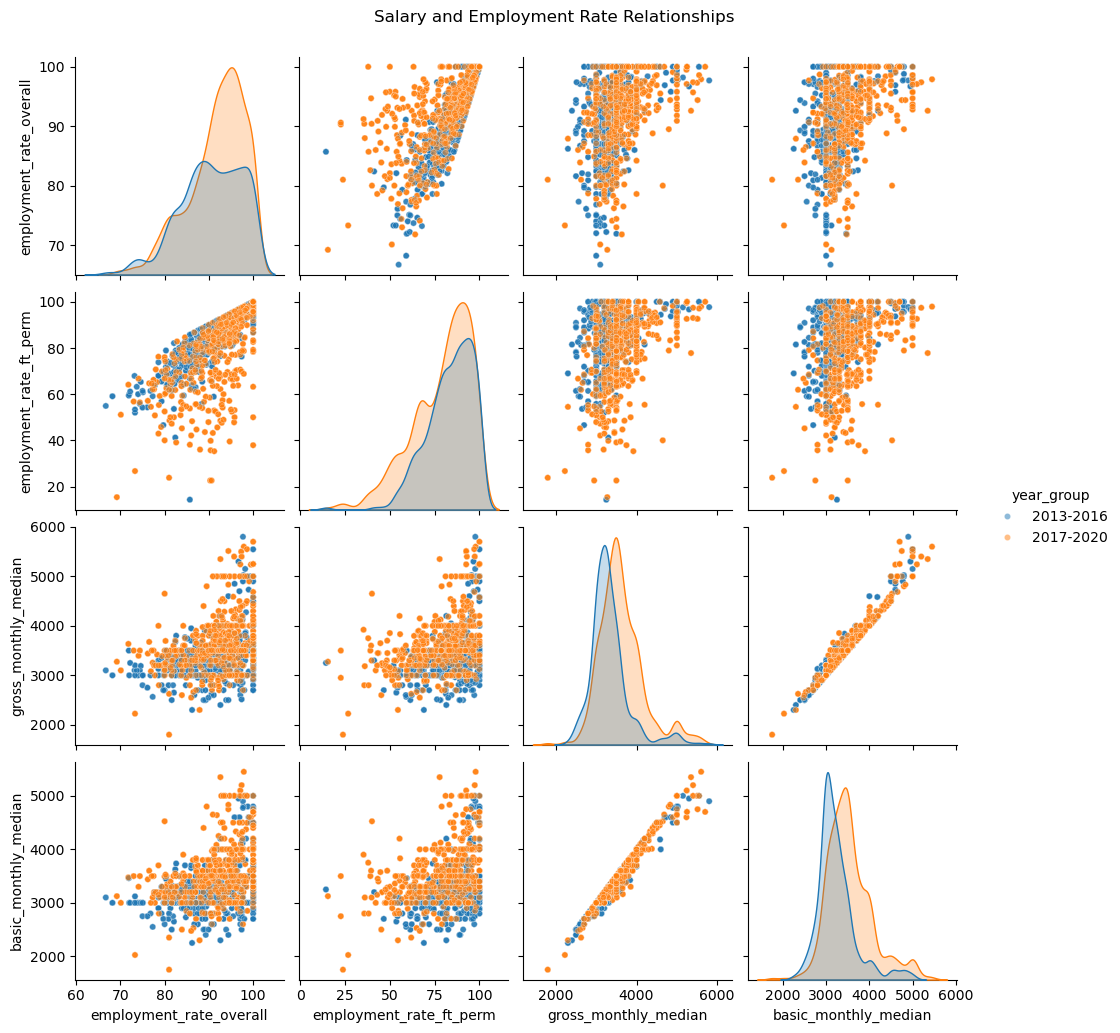

In [7]:
#pairplot

merged['year_group'] = merged['year'].apply(lambda y: '2013-2016' if y <= 2016 else '2017-2020')
cols = ['employment_rate_overall', 'employment_rate_ft_perm', 'gross_monthly_median', 'basic_monthly_median']
sns.pairplot(merged, vars=cols, diag_kind='kde', hue='year_group', plot_kws={'alpha': 0.5, 's': 20}).fig.suptitle('Salary and Employment Rate Relationships', y=1.03)


**Analysis of Pairplot**

The pairplot shows relationships between four variables — overall employment rate, full-time permanent employment rate, median gross monthly salary, and median basic monthly salary — split into two year groups (2013-2016 vs 2017-2020).

**Key findings:**
- Median gross and basic monthly salaries are strongly positively correlated across all years.
- Higher employment rates (overall and full-time permanent) tend to be associated with higher salaries.
- The 2017-2020 group shows slightly higher densities at higher salary levels than 2013-2016.
- Employment rate distributions are similar across both year groups, with only modest shifts.

**Contribution to research question:** This chart gives a baseline view of how salary and employment outcomes move together over time. It shows a modest upward shift in salaries but no major change in employment rate distribution — suggesting the overall labour market backdrop was fairly stable, which matters for interpreting whether any change in the "degree advantage" is coming from the degree itself or from broader market shifts.

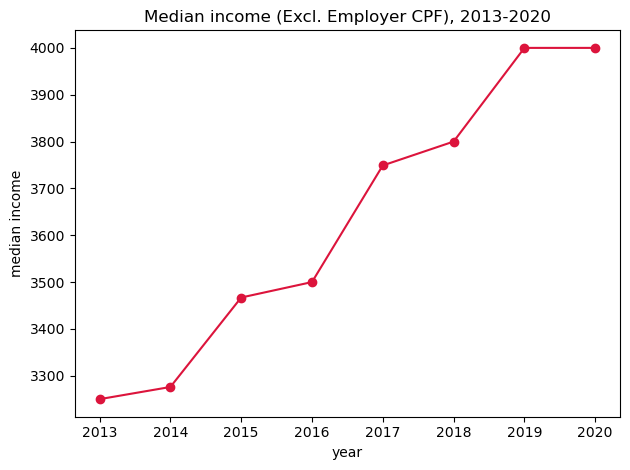

In [12]:
df_line = df4.drop(columns=['median_income_incl_emp_cpf'])
df_lineFiltered = df4[(df4['year']>=2013) & (df4['year']<=2020)]
plt.plot(df_lineFiltered['year'], df_lineFiltered['median_income_excl_emp_cpf'],  marker='o', color='crimson')
plt.title("Median income (Excl. Employer CPF), 2013-2020")
plt.xlabel("year")
plt.ylabel("median income")
plt.tight_layout()

**Analysis of Line Chart — Median Income Trend (2013 - 2020)**

Median income (excluding employer CPF) rises from roughly \$3,250 in 2013 to about \$4,000 by 2019 - 2020.

**Key findings:**
- Income increases in every year between 2013 and 2019.
- The steepest single-year rise is between 2016 and 2017.
- Income plateaus between 2019 and 2020 at around \$4,000.
-  Overall growth across the period is roughly \$750.

**Contribution to research question:** This chart establishes the national income baseline that graduate salaries are being compared against. It shows steady national income growth followed by a 2019-2020 plateau (likely COVID-related), but on its own it can't separate degree holders from the wider workforce — it's context for the comparisons in the other charts, not direct evidence either way.

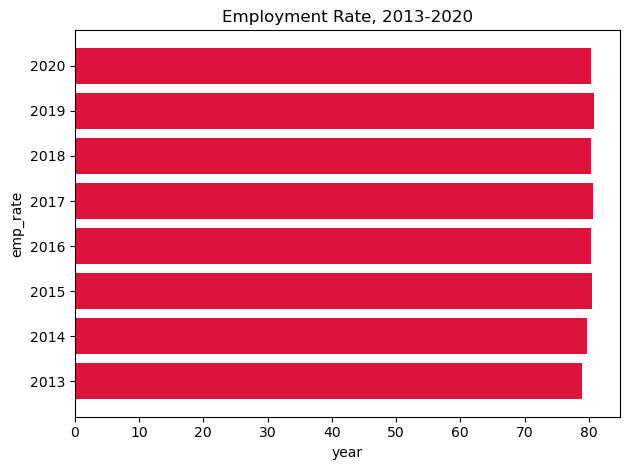

In [13]:
df1_BarFiltered = df5[(df5['year']>=2013) & (df5['year']<=2020)]
df1_BarFiltered
plt.barh(df1_BarFiltered['year'],df1_BarFiltered['emp_rate'], color='crimson')
plt.title("Employment Rate, 2013-2020")
plt.xlabel("year")
plt.ylabel("emp_rate")
plt.tight_layout()

**Analysis of Bar Chart — National Employment Rate (2013 - 2020)**

Employment rates stay clustered around the low-80% range across all 8 years.

**Key findings:**
- Employment rates are consistently high in every year shown.
- A slight rise from 2013 to 2014.
- Rates are nearly flat from 2014 through 2019.
- 2020 is very close to 2019, with no clear COVID-driven decline visible at this national scale.

**Contribution to research question:** This chart doesn't distinguish degree holders from the general workforce, so it can't tell us whether the degree advantage in stability changed. What it does show is that any change in that advantage over 2013 - 2020 is unlikely to be driven by big swings in the overall national employment rate, the national baseline itself was steady.

Text(0.5, 1.05, 'Income Distribution: Degree vs Non-Degree Holders, 2013 vs 2020')

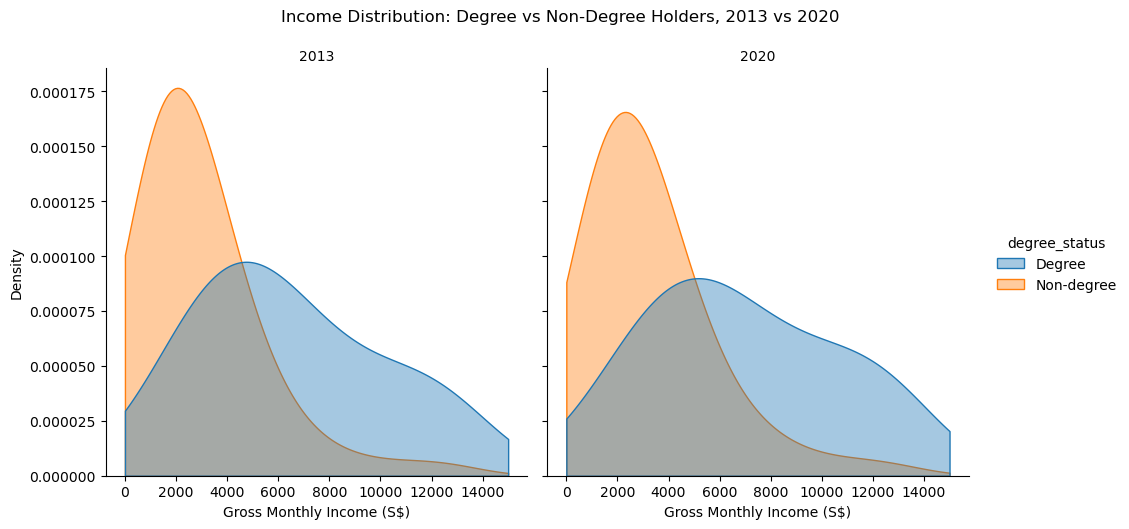

In [9]:
df3['degree_status'] = df3['highest_qualification'].apply(
    lambda x: 'Degree' if str(x).strip().lower() == 'degree' else 'Non-degree'
)
df3['employed'] = pd.to_numeric(df3['employed'], errors='coerce').fillna(0).astype(int)

kde_years = df3[df3['year'].isin([2013, 2020])].copy()
kde_years['income_midpoint'] = kde_years['gross_monthly_income_excl_emr_cpf'].map(salary_midpoints)
kde_years = kde_years.dropna(subset=['income_midpoint'])

kde_grouped = kde_years.groupby(
    ['year', 'degree_status', 'income_midpoint'], as_index=False
)['employed'].sum()

g_kde = sns.displot(
    data=kde_grouped,
    x='income_midpoint',
    weights='employed',
    hue='degree_status',
    col='year',
    kind='kde',
    fill=True,
    common_norm=False,
    clip=(0, 15000),
    alpha=0.4,
    height=5, aspect=1
)
g_kde.set_axis_labels('Gross Monthly Income (S$)', 'Density')
g_kde.set_titles('{col_name}')
g_kde.fig.suptitle('Income Distribution: Degree vs Non-Degree Holders, 2013 vs 2020', y=1.05)

**Analysis of KDE Chart — Income Distribution, Degree vs Non-Degree (2013 vs 2020)**

Compares income distribution shape for degree and non-degree holders in 2013 and in 2020.

**Key findings:**
- Non-degree holders show a sharp, narrow peak around \$2,000-2,500 in both years — this peak barely moves between 2013 and 2020.
- Degree holders show a broader, flatter distribution that shifts noticeably to the right: peak income rises from around \$4,500 in 2013 to \$5,000-5,500 in 2020, with density extending further into the $10,000-15,000 range by 2020.
- Because the non-degree distribution stays largely fixed while the degree distribution moves right, the income gap between the two groups widens slightly rather than staying constant.
- Overlap between the two groups remains limited in both years, especially at higher income levels.

**Contribution to research question:** Unlike the pooled boxplot, this chart can actually compare 2013 vs 2020 directly — and it suggests the degree income advantage widened slightly over the period, driven mainly by degree holders' incomes rising while non-degree incomes stayed flat. This is worth flagging as it creates a genuine point of tension with the boxplot/bar chart evidence (which reads as more "stable") — that tension is actually good, since your research question explicitly expects indicators that can conflict, and your conclusion should address it rather than smooth it over.

In [ ]:
box_df = df3[(df3["year"] >= 2013) & (df3["year"] <= 2020)].copy()
box_df = box_df[box_df["degree_status"].isin(["Degree", "Non-degree"])]

box_df["salary_midpoint"] = box_df["gross_monthly_income_excl_emr_cpf"].map(salary_midpoints)
box_df["employed"] = pd.to_numeric(box_df["employed"], errors="coerce").fillna(0).astype(int)

expanded = []
for _, row in box_df.iterrows():
    repeats = max(1, row["employed"] // 100)
    expanded.extend(
        [{"degree_status": row["degree_status"], "salary": row["salary_midpoint"]}] * repeats
    )
expanded_df = pd.DataFrame(expanded)

plt.figure(figsize=(8, 6))
sns.boxplot(
    data=expanded_df,
    x="degree_status",
    y="salary",
    hue="degree_status",
    palette="Set2",
    legend=False
)
plt.title("Estimated Salary Distribution\nDegree vs Non-degree (2013-2020)")
plt.xlabel("Education Level")
plt.ylabel("Estimated Monthly Salary (SGD)")
plt.tight_layout()
plt.savefig("boxplot.png", dpi=300, bbox_inches="tight")

print("All 5 charts saved: pairplot.png, line_chart.png, bar_chart.png, kde_chart.png, boxplot.png")

**Analysis of Boxplot — Salary Distribution, Degree vs Non-Degree (2013–2020, pooled)**

Compares estimated monthly salary spread for degree vs non-degree holders across the whole period.

**Key findings:**
- Median salary for degree holders is visibly higher than for non-degree holders.
- The interquartile range (IQR) for degree holders sits higher, indicating generally higher typical salaries, not just a few high earners.
- The upper whisker for degree holders exceeds that of non-degree holders.
- Both groups have outliers at the high end, but non-degree outliers stay below the main upper range of degree holders.

**Contribution to research question:** This confirms a clear salary premium for degree holders across the pooled 2013–2020 period. Because it's pooled across years, it can't show whether the premium grew or shrank — but combined with the KDE chart's year-by-year view, it supports the conclusion that the advantage is real and persistent rather than a one-off.

**Conclusion**

The macro picture is stable: employment rates hold steady around 80% from 2013–2020 (bar chart), median income rises steadily before plateauing in 2019–2020 (line chart), and salary/employment rates move together with only modest shifts across year groups (pairplot). Nothing here points to a dramatic structural change in the labour market over this period.

The degree-specific evidence tells a sharper story, though. The pooled boxplot confirms a clear, persistent salary premium for degree holders across 2013-2020. The KDE chart adds a time dimension the boxplot lacks — non-degree incomes stay anchored around \$2,000-2,500 in both 2013 and 2020, while degree-holder incomes shift from a \$4,500 peak to \$5,000-5,500 over the same period, suggesting the premium widened rather than stayed flat.

**Verdict:** The overall employment and income environment in Singapore was broadly stable over 2013-2020, but within that stable environment, the specific advantage of holding a degree appears to have widened rather than shrunk — degree holders captured a disproportionate share of the income growth over this period, while non-degree incomes stayed largely static. This reflects exactly the kind of conflicting-indicator scenario the research question is built around: macro-level stability coexisting with a growing individual-level premium.